# Multiple Object Video Detection
## One-stage anchor based (RetinaNet)

Downloading scripts and chepoints fro google drive

In [14]:
import os, sys, subprocess
from pathlib import Path
from google.colab import drive, userdata

drive.mount("/content/drive", force_remount=True)
BASE = Path("/content/drive/MyDrive/ai-hw2")
CODE, RUNS, REPORT = BASE / "code", BASE / "runs", BASE / "eda_report"
for p in (CODE, RUNS, REPORT):
    p.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(CODE))

needed = ["scripts/eda.py", "scripts/fr_cnn.py", "scripts/run_experiments.py", "scripts/analyze_model.py", "scripts/detection_errors.py", "scripts/anchor_analysis.py", "scripts/retinanet.py", "scripts/run_retina_net.py", "scripts/analyze_retina_net.py", "scripts/make_submission.py"]
missing = [f for f in needed if not (CODE / f).exists()]
assert not missing, f"copy these files to {CODE}: {missing}"

subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pycocotools"], check=True)

import torch
print("torch", torch.__version__, "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE - change the runtime type")
print("CPU cores:", os.cpu_count())

os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_ACCESS_TOKEN").strip()

Mounted at /content/drive
torch 2.14.1+cu130 | GPU: Tesla T4
CPU cores: 2


Downloading and extracting the data

In [3]:
!kaggle competitions download -c multiple-object-video-detection-hw-2-ucu-ai-2026
!unzip ./multiple-object-video-detection-hw-2-ucu-ai-2026.zip -d ./object-detection-data

Streaming output truncated to the last 5000 lines.
  inflating: ./object-detection-data/val/images/uav0000117_02622_v/0000229.jpg  
  inflating: ./object-detection-data/val/images/uav0000117_02622_v/0000230.jpg  
  inflating: ./object-detection-data/val/images/uav0000117_02622_v/0000231.jpg  
  inflating: ./object-detection-data/val/images/uav0000117_02622_v/0000232.jpg  
  inflating: ./object-detection-data/val/images/uav0000117_02622_v/0000233.jpg  
  inflating: ./object-detection-data/val/images/uav0000117_02622_v/0000234.jpg  
  inflating: ./object-detection-data/val/images/uav0000117_02622_v/0000235.jpg  
  inflating: ./object-detection-data/val/images/uav0000117_02622_v/0000236.jpg  
  inflating: ./object-detection-data/val/images/uav0000117_02622_v/0000237.jpg  
  inflating: ./object-detection-data/val/images/uav0000117_02622_v/0000238.jpg  
  inflating: ./object-detection-data/val/images/uav0000117_02622_v/0000239.jpg  
  inflating: ./object-detection-data/val/images/uav0000117

### Preparing the dataset

In [4]:
import scripts.eda as eda
DATA_ROOT = Path("./object-detection-data")
PREPARED = Path("/content/prepared")
STEP = 3
if not (PREPARED / "data.yaml").exists():
    eda.rebuild_dataset(DATA_ROOT, PREPARED, STEP)
print("prepared dataset:", PREPARED)

OK: every clip belongs to exactly one split
Split summary
       clips  frames  objects  objs_per_frame
split                                        
train     55   22481  1013421            45.1
val        8    4566   206227            45.2
Class mix per split [%]
       person  bicycle    car   van  truck  tricycle   bus  motor
split                                                            
train   30.75     3.76  43.94  4.30   2.43      4.02  0.63  10.18
val     32.67     3.98  44.55  4.96   3.49      2.96  1.72   5.66
Subsampling step 3: 27047 -> 9041 frames

wrote 9041 frames to /content/prepared
prepared dataset: /content/prepared


### Investigating the anchors



object size at imgsz=1536: p5 16.9  median 38.0  p95 106.5 px;  aspect h/w p10/p50/p90 = [0.47, 1.07, 2.26]
derived: {'anchor_base': (17, 34, 68, 136, 272), 'aspect_ratios': (0.5, 1.1, 2.3)}

  share of GT whose best anchor has IoU >= 0.5  
                     anchors_per_location  mean_best_iou  covered all  covered <8  covered 8-16  covered 16-32  covered >=32
config                                                                                                                      
default                                 9          0.684        0.863         0.0         0.000          0.687         0.999
data sizes                              9          0.675        0.978         0.0         0.600          0.990         0.997
data sizes + ratios                     9          0.675        0.976         0.0         0.562          0.990         0.997

  default: coverage by object size (input px)  
          n_gt  mean_best_iou  share>=0.3  share>=0.4  share>=0.5  share>=0.6
size_px

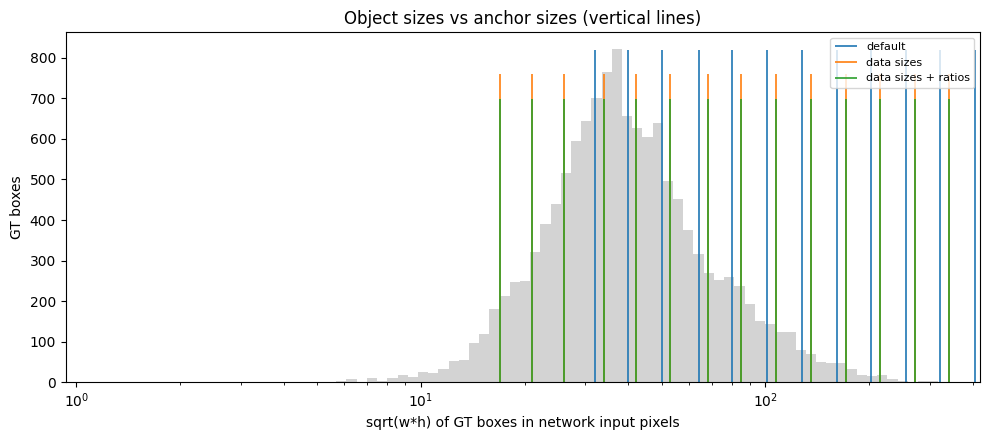

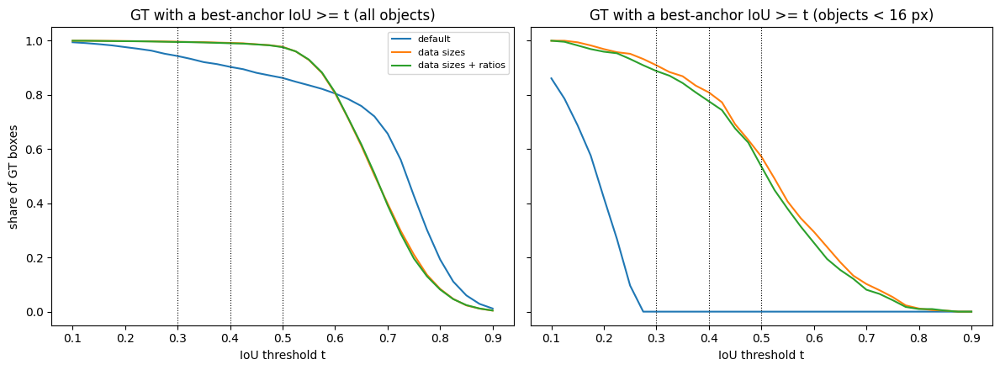

In [5]:
import json
import scripts.run_retina_net as RR
import scripts.retinanet as RL
from dataclasses import replace

rbase = RL.RetinaConfig(data_root=str(PREPARED), out_dir=str(RUNS / "retina_tune"), imgsz=1536,
                        epochs=3, train_stride=2, batch_size=4)
derived = RR.anchor_study(rbase, RUNS / "retina_tune" / "anchor_study")

First step of tuning this model was checking and comparing anchor sizes. At image size 1536 the median size of our object is 38 px and 5% is 16.9 px. Because of this we can't use torchvision default anchors, as they start at 32px. So we will use our custom anchor sizes, which start at 5% and grow twice at each level. This raised our coverage from default 86% to 97.8%.



### Smoke test and tuning


In [6]:
import scripts.run_experiments as R
import scripts.fr_cnn as L
device = L.get_device()

In [7]:
smoke_r = replace(rbase, out_dir="/content/smoke", epochs=1, train_stride=100, val_stride=20, warmup_iters=5)
row = R.run_experiment("smoke_retina", smoke_r, L.get_device(), force=True, build_fn=RL.build_retinanet,
                       describe_fn=RL.describe_retina_setup, params=RR.retina_params(smoke_r))
print({k: row[k] for k in ("mAP", "AP50", "AP_small", "ms_per_img")})

Downloading: "https://download.pytorch.org/models/retinanet_resnet50_fpn_coco-eeacb38b.pth" to /root/.cache/torch/hub/checkpoints/retinanet_resnet50_fpn_coco-eeacb38b.pth


100%|██████████| 130M/130M [00:00<00:00, 177MB/s]


[smoke_retina] 76 train frames, 19 it/epoch, 19 iterations in total
[smoke_retina] epoch 1/1: classification 0.915, bbox_regression 0.370, loss 1.284
[smoke_retina] mAP 0.038  AP50 0.070  AP_small 0.005  95 ms/img
{'mAP': 0.03797388135580284, 'AP50': np.float64(0.06972106035612083), 'AP_small': np.float64(0.004746450494996281), 'ms_per_img': 94.52772762687576}


In [ ]:
stages = RR.build_stages(derived)
stages[0][1].pop("data_sizes_ratios", None)
stages[2][1].pop("alpha0.5", None)
df_r, tuned = RR.run_tuning(rbase, stages, L.get_device())

[initial] found /content/drive/MyDrive/ai-hw2/runs/retina_tune/initial/metrics.json, skipping (use --force to retrain)
[anchors_data_sizes] found /content/drive/MyDrive/ai-hw2/runs/retina_tune/anchors_data_sizes/metrics.json, skipping (use --force to retrain)

>>> stage 'anchors': best = initial (mAP -1.000)

[iou_fg0.4_bg0.3] found /content/drive/MyDrive/ai-hw2/runs/retina_tune/iou_fg0.4_bg0.3/metrics.json, skipping (use --force to retrain)
[iou_fg0.3_bg0.2] found /content/drive/MyDrive/ai-hw2/runs/retina_tune/iou_fg0.3_bg0.2/metrics.json, skipping (use --force to retrain)

>>> stage 'iou': best = iou_fg0.4_bg0.3 (mAP 0.066)

Downloading: "https://download.pytorch.org/models/retinanet_resnet50_fpn_coco-eeacb38b.pth" to /root/.cache/torch/hub/checkpoints/retinanet_resnet50_fpn_coco-eeacb38b.pth


100%|██████████| 130M/130M [00:00<00:00, 168MB/s]


[focal_gamma1] 3758 train frames, 939 it/epoch, 2817 iterations in total
  ep 0 it 50/939 lr 0.00042 loss 1.689
  ep 0 it 100/939 lr 0.00084 loss 1.168
  ep 0 it 150/939 lr 0.00125 loss 0.945
  ep 0 it 200/939 lr 0.00167 loss 0.848
  ep 0 it 250/939 lr 0.00208 loss 0.774
  ep 0 it 300/939 lr 0.00250 loss 0.792
  ep 0 it 350/939 lr 0.00250 loss 0.741
  ep 0 it 400/939 lr 0.00249 loss 0.708
  ep 0 it 450/939 lr 0.00248 loss 0.689
  ep 0 it 500/939 lr 0.00246 loss 0.697
  ep 0 it 550/939 lr 0.00244 loss 0.661
  ep 0 it 600/939 lr 0.00241 loss 0.675
  ep 0 it 650/939 lr 0.00238 loss 0.666
  ep 0 it 700/939 lr 0.00235 loss 0.648
  ep 0 it 750/939 lr 0.00231 loss 0.627
  ep 0 it 800/939 lr 0.00227 loss 0.615
  ep 0 it 850/939 lr 0.00222 loss 0.634
  ep 0 it 900/939 lr 0.00217 loss 0.603
[focal_gamma1] epoch 1/3: classification 0.441, bbox_regression 0.339, loss 0.780
  ep 1 it 50/939 lr 0.00207 loss 0.602
  ep 1 it 100/939 lr 0.00201 loss 0.591
  ep 1 it 150/939 lr 0.00195 loss 0.593
  ep 1 

In [ ]:
import pandas as pd
import json
rows = []
for run in sorted((RUNS / "retina_tune").iterdir()):
    if (run / "config.json").exists() and (run / "metrics.json").exists():
        c, m = (json.loads((run / f).read_text()) for f in ("config.json", "metrics.json"))
        rows.append({"run": run.name, **{k: c.get(k) for k in ("imgsz", "epochs", "train_stride", "batch_size",
                     "lr", "anchor_base", "fg_iou_thresh", "focal_gamma")}, "mAP": m["mAP"], "AP50": m["AP50"]})
pd.DataFrame(rows)

,run,imgsz,epochs,train_stride,batch_size,lr,anchor_base,fg_iou_thresh,focal_gamma,mAP,AP50
0,anchors_data_sizes,640,3,2,4,0.0025,"[7, 14, 28, 56, 112]",0.5,2.0,-1.000000,0.098719
1,anchors_data_sizes_ratios,640,3,2,4,0.0025,"[7, 14, 28, 56, 112]",0.5,2.0,-1.000000,0.096524
2,focal_gamma1,1536,3,2,4,0.0025,"[32, 64, 128, 256, 512]",0.4,1.0,0.132411,0.253601
3,initial,640,3,2,4,0.0025,"[32, 64, 128, 256, 512]",0.5,2.0,-1.000000,0.133282
4,iou_fg0.3_bg0.2,640,3,2,4,0.0025,"[32, 64, 128, 256, 512]",0.3,2.0,0.051972,0.105932
5,iou_fg0.4_bg0.3,640,3,2,4,0.0025,"[32, 64, 128, 256, 512]",0.4,2.0,0.065969,0.138124


In [9]:
import scripts.retinanet as RL
import scripts.run_experiments as R
import scripts.run_retina_net as RR
import scripts.fr_cnn as L

In [ ]:
import shutil
out = RUNS / "retina_tune_1536"
base1536 = RL.RetinaConfig(data_root=str(PREPARED), out_dir=str(out), imgsz=1536, epochs=3, train_stride=2, batch_size=4)
_, derived1536 = RR.data_driven_anchors(base1536)
print("anchors derived at 1536:", derived1536)

new_runs = {"initial_1536": {},
            "anchors_1536": {"anchor_base": derived1536["anchor_base"],
                             "fg_iou_thresh": 0.4, "bg_iou_thresh": 0.3, "focal_gamma": 1.0}}
for name, ov in new_runs.items():
    cfg = R.apply_overrides(base1536, ov)
    R.run_experiment(name, cfg, L.get_device(), build_fn=RL.build_retinanet, describe_fn=RL.describe_retina_setup, params=RR.retina_params(cfg))


anchors derived at 1536: {'anchor_base': (17, 34, 68, 136, 272), 'aspect_ratios': (0.5, 1.1, 2.3)}
Downloading: "https://download.pytorch.org/models/retinanet_resnet50_fpn_coco-eeacb38b.pth" to /root/.cache/torch/hub/checkpoints/retinanet_resnet50_fpn_coco-eeacb38b.pth


100%|██████████| 130M/130M [00:00<00:00, 150MB/s]


[initial_1536] 3758 train frames, 939 it/epoch, 2817 iterations in total
  ep 0 it 50/939 lr 0.00042 loss 1.407
  ep 0 it 100/939 lr 0.00084 loss 0.884
  ep 0 it 150/939 lr 0.00125 loss 0.735
  ep 0 it 200/939 lr 0.00167 loss 0.660
  ep 0 it 250/939 lr 0.00208 loss 0.616
  ep 0 it 300/939 lr 0.00250 loss 0.623
  ep 0 it 350/939 lr 0.00250 loss 0.584
  ep 0 it 400/939 lr 0.00249 loss 0.566
  ep 0 it 450/939 lr 0.00248 loss 0.559
  ep 0 it 500/939 lr 0.00246 loss 0.555
  ep 0 it 550/939 lr 0.00244 loss 0.536
  ep 0 it 600/939 lr 0.00241 loss 0.540
  ep 0 it 650/939 lr 0.00238 loss 0.532
  ep 0 it 700/939 lr 0.00235 loss 0.521
  ep 0 it 750/939 lr 0.00231 loss 0.507
  ep 0 it 800/939 lr 0.00227 loss 0.500
  ep 0 it 850/939 lr 0.00222 loss 0.515
  ep 0 it 900/939 lr 0.00217 loss 0.495
[initial_1536] epoch 1/3: classification 0.321, bbox_regression 0.303, loss 0.624
  ep 1 it 50/939 lr 0.00207 loss 0.497
  ep 1 it 100/939 lr 0.00201 loss 0.489
  ep 1 it 150/939 lr 0.00195 loss 0.482
  ep 1 

In [9]:
df_r, tuned = RR.run_tuning(rbase, RR.build_stages(derived), device)

[initial] found /content/drive/MyDrive/ai-hw2/runs/retina_tune/initial/metrics.json, skipping (use --force to retrain)
[anchors_data_sizes] found /content/drive/MyDrive/ai-hw2/runs/retina_tune/anchors_data_sizes/metrics.json, skipping (use --force to retrain)
[anchors_data_sizes_ratios] found /content/drive/MyDrive/ai-hw2/runs/retina_tune/anchors_data_sizes_ratios/metrics.json, skipping (use --force to retrain)

>>> stage 'anchors': best = initial (mAP 0.063)

[iou_fg0.4_bg0.3] found /content/drive/MyDrive/ai-hw2/runs/retina_tune/iou_fg0.4_bg0.3/metrics.json, skipping (use --force to retrain)
[iou_fg0.3_bg0.2] found /content/drive/MyDrive/ai-hw2/runs/retina_tune/iou_fg0.3_bg0.2/metrics.json, skipping (use --force to retrain)

>>> stage 'iou': best = iou_fg0.4_bg0.3 (mAP 0.066)

[focal_gamma1] found /content/drive/MyDrive/ai-hw2/runs/retina_tune/focal_gamma1/metrics.json, skipping (use --force to retrain)
[focal_gamma3] found /content/drive/MyDrive/ai-hw2/runs/retina_tune/focal_gamma3/m

In [13]:
import scripts.run_experiments as R

In [15]:
R.reevaluate_run(RUNS/ "retina_tune"/ "initial", kind = 'retina')
R.reevaluate_run(RUNS/ "retina_tune"/ "anchors_data_sizes", kind = 'retina')
R.reevaluate_run(RUNS/ "retina_tune"/ "anchors_data_sizes_ratios", kind = 'retina')

[initial] mAP 0.063  AP50 0.133  AP_small 0.007
[anchors_data_sizes] mAP 0.028  AP50 0.099  AP_small 0.012
[anchors_data_sizes_ratios] mAP 0.027  AP50 0.097  AP_small 0.011


{'experiment': 'anchors_data_sizes_ratios',
 'anchor_base': '(7, 14, 28, 56, 112)',
 'aspect_ratios': '(0.5, 1.1, 2.3)',
 'fg_iou': 0.5,
 'bg_iou': 0.4,
 'alpha': 0.25,
 'gamma': 2.0,
 'epochs': 3,
 'train_stride': 2,
 'train_min': 46.72686208486557,
 'mAP': 0.027104310669746952,
 'AP50': np.float64(0.09655945785916153),
 'AP75': np.float64(0.007873525401180876),
 'AP_small': np.float64(0.011346090727841691),
 'AP_medium': np.float64(0.027015881506648135),
 'AP_large': np.float64(0.06742710951412384),
 'AR500': np.float64(0.14353147481761558),
 'AR_small': np.float64(0.08365394399159187),
 'AP_person': 0.03975622398935943,
 'AP_bicycle': 0.003688636006199677,
 'AP_car': 0.1139755586825714,
 'AP_van': 0.009029221410695072,
 'AP_truck': 0.004354116812366405,
 'AP_tricycle': 0.00415658488400955,
 'AP_bus': 0.01735343911751431,
 'AP_motor': 0.02452070445525981,
 'ms_per_img': 24.146933033383295,
 'ms_median': 23.549236500457482,
 'fps': 41.413126818941905,
 'device': 'Tesla T4'}

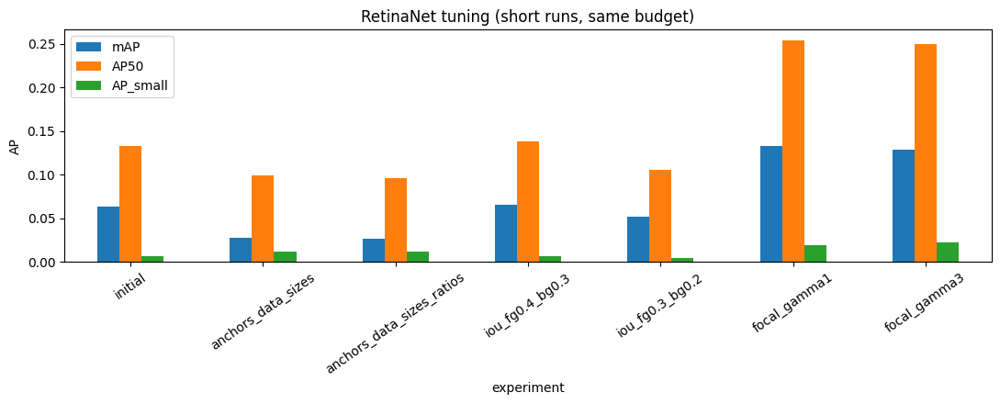

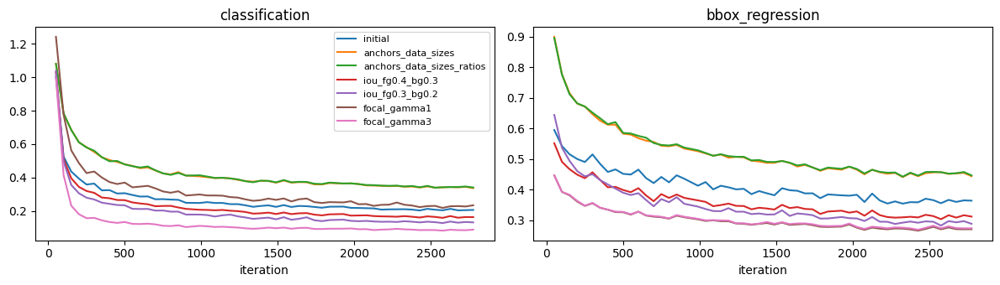

,stage,experiment,anchor_base,aspect_ratios,fg_iou,bg_iou,alpha,gamma,mAP,AP50,AP_small,AP_medium,AP_large,ms_per_img,train_min
0,initial,initial,"(32, 64, 128, 256, 512)","(0.5, 1.0, 2.0)",0.5,0.4,0.25,2.0,0.063,0.133,0.007,0.037,0.228,24.870,49.140
1,anchors,anchors_data_sizes,"(7, 14, 28, 56, 112)","(0.5, 1.0, 2.0)",0.5,0.4,0.25,2.0,0.028,0.099,0.012,0.029,0.060,33.053,46.827
2,anchors,anchors_data_sizes_ratios,"(7, 14, 28, 56, 112)","(0.5, 1.1, 2.3)",0.5,0.4,0.25,2.0,0.027,0.097,0.011,0.027,0.067,24.147,46.727
3,iou,iou_fg0.4_bg0.3,"(32, 64, 128, 256, 512)","(0.5, 1.0, 2.0)",0.4,0.3,0.25,2.0,0.066,0.138,0.006,0.039,0.228,24.458,47.049
4,iou,iou_fg0.3_bg0.2,"(32, 64, 128, 256, 512)","(0.5, 1.0, 2.0)",0.3,0.2,0.25,2.0,0.052,0.106,0.004,0.029,0.195,30.882,47.032
5,focal,focal_gamma1,"(32, 64, 128, 256, 512)","(0.5, 1.0, 2.0)",0.4,0.3,0.25,1.0,0.132,0.254,0.020,0.112,0.284,96.359,54.216
6,focal,focal_gamma3,"(32, 64, 128, 256, 512)","(0.5, 1.0, 2.0)",0.4,0.3,0.25,3.0,0.129,0.250,0.022,0.109,0.281,91.348,53.744


In [10]:
from scripts.eda import finish_figure
finish_figure(RR.plot_tuning(df_r), "tuning", RUNS / "retina_tune", show=True)
finish_figure(R.plot_loss_curves([RUNS / "retina_tune" / n for n in df_r["experiment"]]), "loss_curves",
              RUNS / "retina_tune", show=True)
df_r[[c for c in RR.TABLE_COLS if c in df_r]].round(3)

The next step of tuning the parameters was checking if using custom anchors yielded any results. Sadly, this only weakened model's performance. The main reason is that even though our anchors covered 97.6% of all object they were too small for medium and large objects and caused AP_medium and AP_large to drop, which dropped mAP too.

Our next step was tuning foreground and background IoU. Because our dataset contains frames with a big amount of objects which can overlap, we wanted to check if relaxing those thresholds a bit will make it easier for model to capture those. Lowering foreground IoU from default 0.5 to 0.4 and background IoU from 0.4 to 0.3 did increase mAP but only by 0.03(from 0.63 on initial model to 0.66). We tried lowering both of those 0.1 more but that only lowered the score.

The other parameter we decided to tune focal loss focusing parameter because our dataset is highly imbalanced and this focal loss controls how much the model is penalized for missing rare classes in comparison to popular classes. Setting focal_gamma to 1.0 really improved our results. 

### Tuning final model

In [ ]:
tuned = json.loads((RUNS / "retina_tune" / "tuned_overrides.json").read_text())
print("tuned settings:", tuned)
rfinal = replace(rbase, out_dir=str(RUNS / "retina_final"), epochs=12, train_stride=1)
final_rows = RR.run_final(rfinal, tuned, device)

### Error analysis of the tuned RetinaNet

Best-anchor coverage of the validation objects, outcome of every GT box ("no_proposal" = no anchor with IoU ≥ 0.5), class confusion and failure frames.

collecting detections for 1525 validation frames ...

--- validation GT: share whose best anchor reaches IoU >= thr (sizes in input px) ---
          n_gt  mean_best_iou  share>=0.3  share>=0.4  share>=0.5  share>=0.6
size_px                                                                      
all      68969          0.618       0.900       0.809       0.722       0.637
<8          18          0.060       0.000       0.000       0.000       0.000
8-16      4722          0.194       0.000       0.000       0.000       0.000
16-32    31895          0.533       0.932       0.735       0.548       0.373
>=32     32334          0.765       1.000       1.000       1.000       0.990

--- GT outcomes at score >= 0.3, IoU 0.5 ---
outcome
detected           0.565
class_confusion    0.062
mislocalised       0.102
no_proposal        0.149
not_scored         0.122

--- confident detections (score >= 0.3) ---
outcome
tp                 0.548
duplicate          0.024
class_confusion    0.174
misloca

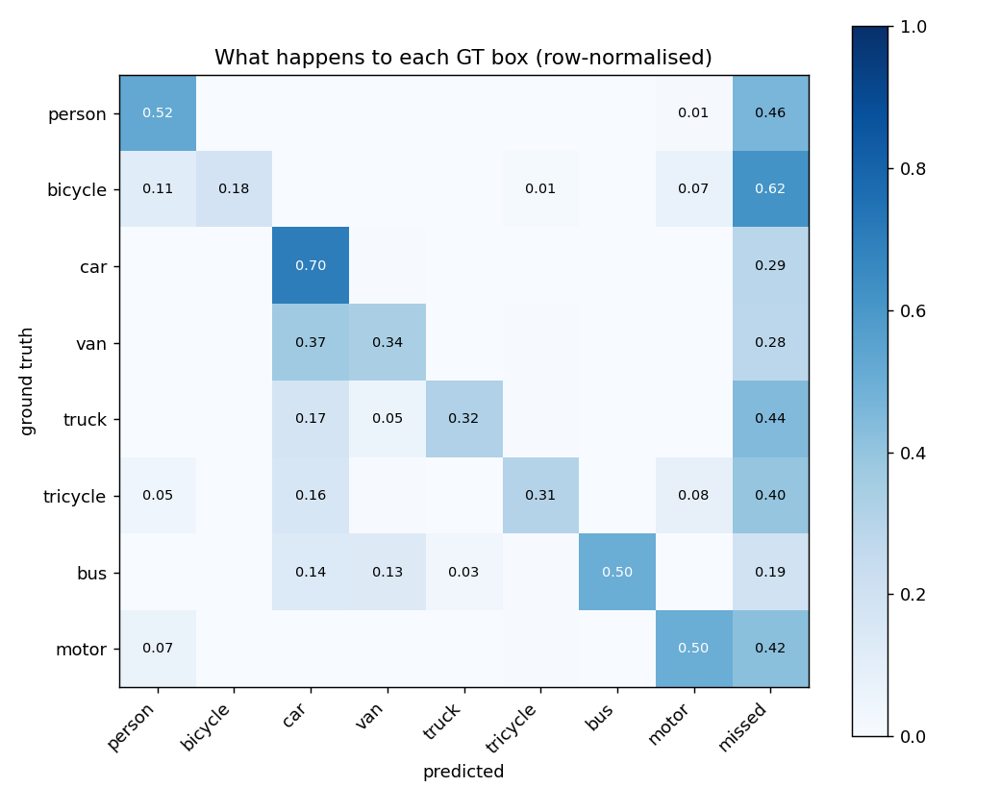

failure_cases.png


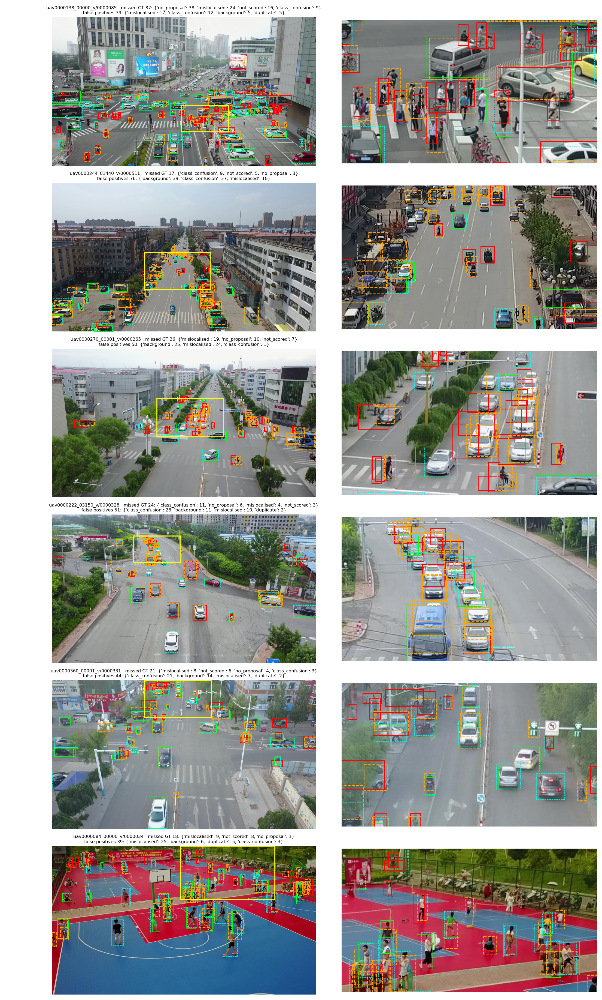

outcomes_by_class.png


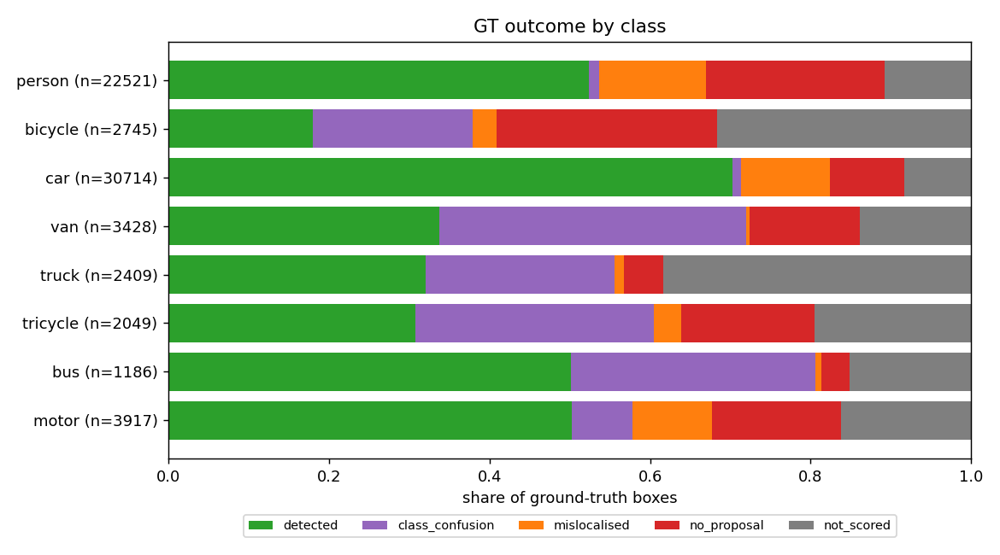

outcomes_by_clip.png


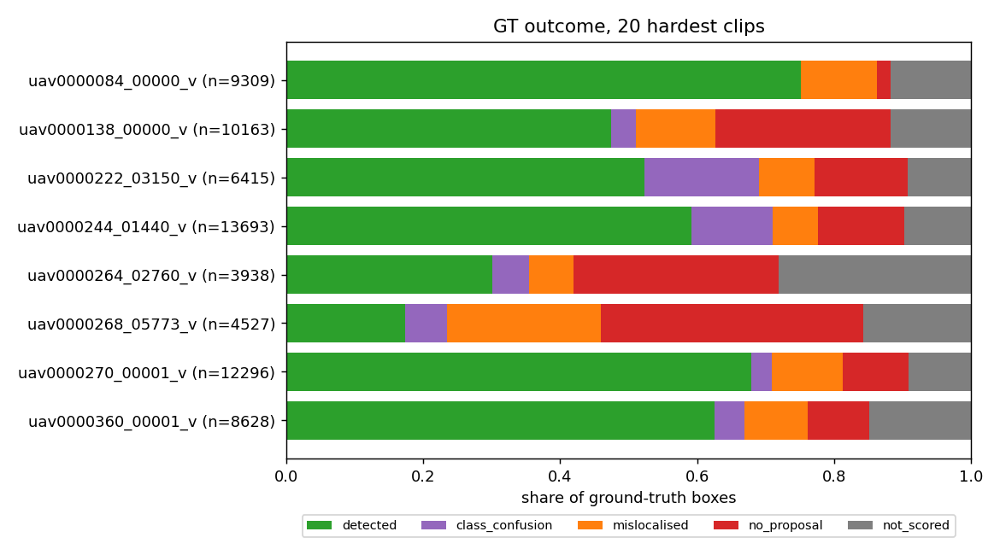

outcomes_by_size.png


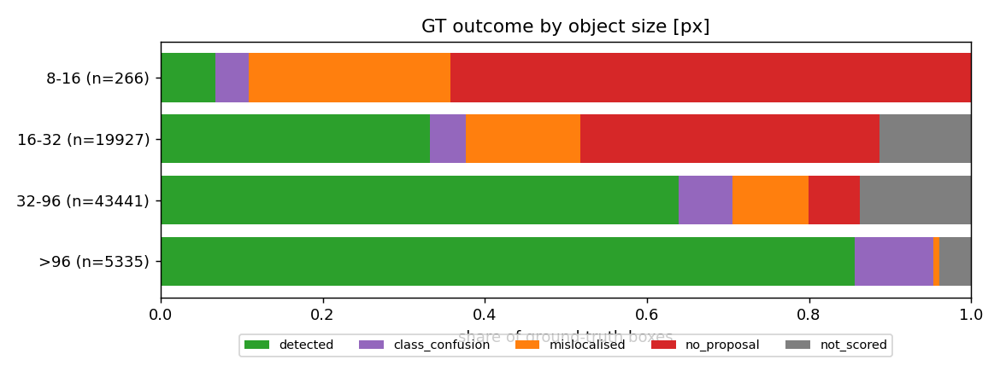

In [16]:
import scripts.analyze_retina_net as AR
from IPython.display import Image, display

run = RUNS / "retina_tune_1536" / "initial_1536"
records_r, gt_r, det_r = AR.analyze_retinanet(run, score_thr=0.3, n_failures=6)
for f in sorted((run / "analysis").glob("*.png")):
    print(f.name)
    display(Image(str(f)))

Similarly to FasterCNN, we see the model struggling with small objects. The highest percentage of missed is across rare and small in terms of size categories, such as bicycles, tricicles and motorcicles. What differs from FasterCNN is much higher rate of false positives, which is the main consequence of removing the first stage.

### Initial vs tuned RetinaNet vs tuned Faster R-CNN

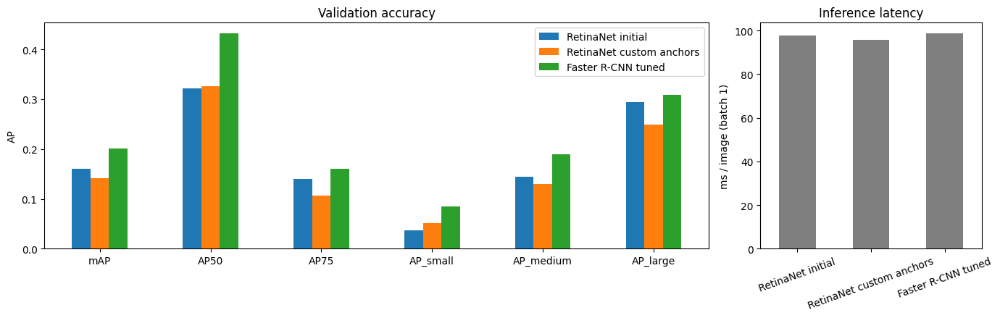

,mAP,AP50,AP75,AP_small,AP_medium,AP_large,AR500,ms_per_img,fps,train_min
RetinaNet initial,0.160,0.322,0.139,0.037,0.145,0.294,0.285,97.803,10.225,54.704
RetinaNet custom anchors,0.142,0.327,0.107,0.051,0.130,0.249,0.294,95.554,10.465,54.832
Faster R-CNN tuned,0.201,0.432,0.161,0.085,0.189,0.309,0.367,98.633,10.139,77.099


,AP_person,AP_bicycle,AP_car,AP_van,AP_truck,AP_tricycle,AP_bus,AP_motor
RetinaNet initial,0.178,0.053,0.355,0.102,0.098,0.075,0.322,0.096
RetinaNet custom anchors,0.177,0.063,0.329,0.075,0.071,0.084,0.241,0.096
Faster R-CNN tuned,0.215,0.091,0.387,0.133,0.145,0.131,0.360,0.147


In [23]:
runs = {"RetinaNet initial" : RUNS / "retina_tune_1536" / "initial_1536",
        "RetinaNet custom anchors": RUNS / "retina_tune_1536" / "anchors_1536",
        "Faster R-CNN tuned": RUNS / "final4" / "final4"}
cmp_df, cmp_per_class = RR.compare_models(runs)
out = RUNS / "comparison"
finish_figure(RR.plot_comparison(cmp_df), "model_comparison", out, show=True)
cmp_df.to_csv(out / "model_comparison.csv")
display(cmp_df.round(3))
display(cmp_per_class.round(3))